## Transformers

* Transformers were one of the hottest new ideas in 2019. Transformers were introduced by the paper "Attention is all you need". This is a model architecture for the machine translation task which uses attention to outperform the previous SOTA, sequence-to-sequence models with attention, on many tasks.
* Transformers are a sequence-to-sequence model architecture: they still have a separate encoder and decoder component. The difference is in their use of an improved form of attention known as self-attention, which in addition to its expressive power has the computational advantage that it's expressable as a matrix operation.
* The core architecture consists of a stack of encoders fully connected to a stack of decoders. Each encoder consists of two blocks: a self-attention component, and a feed forward network. Each decoder consists of three blocks: a self-attention component, an encoder-decoder attention component, and a feed forward component.
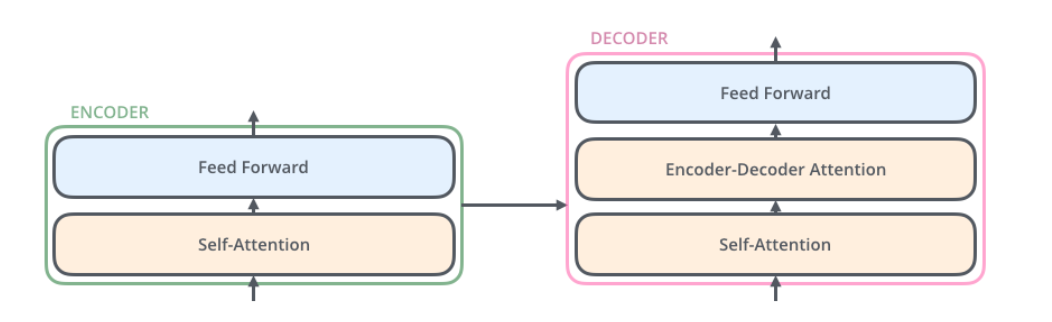

## Self-attention

* Vanilla attention is the use of a (typically linear) combination of previous hidden vectors in the input sequence (a sentence, in the case of a sequence-to-sequence model). This combination of hidden vectors is typically concatenated with the current word's vector and fed to the next layer of the model.
* Here's how attention is typically implemented in slightly more detail (in e.g. the PyTorch documentation's example). A zero matrix is created of sentence length. Each pass through the network populates a column in the matrix with a hidden vector for that word and word position. A hidden vector is generated for the next word. The prior hidden vector matrix is combined via a linear layer into a single combinatorial "prior context" vector, which is then concatenated to current word's hidden vector and passed to the next layer of the network.
* Self-attention is a new spin on the attention technique. Instead of looking at prior hidden vectors when considering a word embedding, self-attention is a weighted combination of all other word embeddings (including those that appear later in the sentence).
* A further innovation of the paper is multi-headed attention. The idea is that by repeating the self-attention mechanism multiple times the model can learn to seperate different kinds of useful semantic information onto different channels (or heads).

## Positional Encodings

* Self-attention is naively position-unaware, e.g. it encoded "The mouse ate the cat." and "The cat ate the mouse." the same way. Contrast this with vanilla attention and with recurrant neural network layers, which are both implicitly position-aware because they process embeddings sequentially.
* Adding this information into the model requires some form of positional encoding. In the paper transformer this is achieved by adding a positional vector to the word embedding prior to input to the self-attention layer. The position vector is a (sin, cos) structure: e.g. the first half of it is a bunch of sin operations on the current position, and the second half is a bunch of cos operations. Adding this to the embedding creates a learnable time dependency in the data; if this positional dependency is important to the task the model can use this information to learn it.

## Installing Libraries

In [2]:
!pip install transformers

     |████████████████████████████████| 4.0 MB 4.2 MB/s 
     |████████████████████████████████| 77 kB 6.2 MB/s 
     |████████████████████████████████| 596 kB 49.0 MB/s 
     |████████████████████████████████| 895 kB 49.6 MB/s 
     |████████████████████████████████| 6.5 MB 32.8 MB/s 
  Attempting uninstall: pyyaml
    Found existing installation: PyYAML 3.13
    Uninstalling PyYAML-3.13:
      Successfully uninstalled PyYAML-3.13


In [3]:
!pip install datasets

     |████████████████████████████████| 325 kB 4.2 MB/s 
     |████████████████████████████████| 1.1 MB 45.1 MB/s 
     |████████████████████████████████| 136 kB 51.4 MB/s 
     |████████████████████████████████| 212 kB 53.4 MB/s 
     |████████████████████████████████| 127 kB 53.6 MB/s 
     |████████████████████████████████| 271 kB 55.5 MB/s 
     |████████████████████████████████| 94 kB 3.5 MB/s 
     |████████████████████████████████| 144 kB 51.9 MB/s 
  Attempting uninstall: urllib3
    Found existing installation: urllib3 1.24.3
    Uninstalling urllib3-1.24.3:
      Successfully uninstalled urllib3-1.24.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datascience 0.10.6 requires folium==0.2.1, but you have folium 0.8.3 which is incompatible.


In [4]:
from datasets import load_dataset
import tensorflow as tf
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
from transformers import DataCollatorWithPadding
import tarfile

## Loading the Dataset

In [5]:
compressed_file = '/content/drive/MyDrive/Colab Notebooks/extra assignment/yelp_review_polarity_csv.tgz'
path = '/content/drive/MyDrive/Colab Notebooks/extra assignment/yelp'

In [6]:

def extract(data):
  tar = tarfile.open(data)
  tar.extractall(path)
  tar.close()
extract(compressed_file)

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
dataset_train = load_dataset('csv',
data_files='/content/drive/MyDrive/Colab Notebooks/extra assignment/yelp/yelp_review_polarity_csv/train.csv',
column_names=['label','text'], split='train[:2%]',engine='python')

Using custom data configuration default-0c5a4e34cda4cb0c


Extracting data files:   0%|          | 0/1 [00:00<?, ?it/s]

Dataset csv downloaded and prepared to /root/.cache/huggingface/datasets/csv/default-0c5a4e34cda4cb0c/0.0.0/433e0ccc46f9880962cc2b12065189766fbb2bee57a221866138fb9203c83519. Subsequent calls will reuse this data.


In [9]:
dataset_test = load_dataset('csv',
data_files={'test':'/content/drive/MyDrive/Colab Notebooks/extra assignment/yelp/yelp_review_polarity_csv/test.csv'},
column_names=['label','text'],split='test[:10%]',engine='python')


Using custom data configuration default-12d3f80c7c18d366


Extracting data files:   0%|          | 0/1 [00:00<?, ?it/s]

Dataset csv downloaded and prepared to /root/.cache/huggingface/datasets/csv/default-12d3f80c7c18d366/0.0.0/433e0ccc46f9880962cc2b12065189766fbb2bee57a221866138fb9203c83519. Subsequent calls will reuse this data.


In [10]:
dataset_train

Dataset({
    features: ['label', 'text'],
    num_rows: 11200
})

In [11]:
dataset_test

Dataset({
    features: ['label', 'text'],
    num_rows: 3800
})

## BERT

In [12]:
checkpoint_bert = 'distilbert-base-uncased'
tokenizer_bert = AutoTokenizer.from_pretrained(checkpoint_bert)
model_bert = TFAutoModelForSequenceClassification.from_pretrained(checkpoint_bert, num_labels=1)


Downloading:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/483 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/226k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/455k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/347M [00:00<?, ?B/s]

Some layers from the model checkpoint at distilbert-base-uncased were not used when initializing TFDistilBertForSequenceClassification: ['vocab_layer_norm', 'vocab_projector', 'vocab_transform', 'activation_13']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFDistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['dropout_19', 'classifier', 'pre_classifier']
You should probably TRAIN this model on a down-stream task to be able to use i

In [31]:
model_bert.summary()

Model: "tf_distil_bert_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 distilbert (TFDistilBertMai  multiple                 66362880  
 nLayer)                                                         
                                                                 
 pre_classifier (Dense)      multiple                  590592    
                                                                 
 classifier (Dense)          multiple                  769       
                                                                 
 dropout_19 (Dropout)        multiple                  0         
                                                                 
Total params: 66,954,241
Trainable params: 769
Non-trainable params: 66,953,472
_________________________________________________________________


In [13]:
for layer in model_bert.layers[:-2]:
 layer.trainable = False


In [14]:
def tokenize_bert(sample):
 return tokenizer_bert(sample['text'], truncation=True)

In [15]:
dataset_tokens_train_bert = dataset_train.map(tokenize_bert, batched=True)

  0%|          | 0/12 [00:00<?, ?ba/s]

In [16]:
dataset_tokens_test_bert = dataset_test.map(tokenize_bert, batched=True)


  0%|          | 0/4 [00:00<?, ?ba/s]

In [17]:
dataset_tokens_train_bert

Dataset({
    features: ['label', 'text', 'input_ids', 'attention_mask'],
    num_rows: 11200
})

In [18]:
dataset_tokens_test_bert

Dataset({
    features: ['label', 'text', 'input_ids', 'attention_mask'],
    num_rows: 3800
})

In [19]:
collate_fn_bert = DataCollatorWithPadding(tokenizer=tokenizer_bert,return_tensors="tf")

In [20]:
train_data_bert = dataset_tokens_train_bert.to_tf_dataset(
 columns=['input_ids','token_type_ids','attention_mask'],
 label_cols=['label'],
 shuffle=True,
 collate_fn=collate_fn_bert,
 batch_size=32
)


In [21]:
test_data_bert = dataset_tokens_test_bert.to_tf_dataset(
 columns=['input_ids','token_type_ids','attention_mask'],
 label_cols=['label'],
 shuffle=False,
 collate_fn=collate_fn_bert,
 batch_size=32
)

In [22]:
model_bert.compile(optimizer='adam', loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=['accuracy'])

In [23]:

tfb_call_bert = tf.keras.callbacks.TensorBoard('/content/drive/MyDrive/Colab Notebooks/extra assignment/yelp/tb_logs_bert',histogram_freq=1)

In [25]:
hist1 = model_bert.fit(train_data_bert, epochs=3, callbacks=[tfb_call_bert])


Epoch 1/3
350/350 [==============================] - 482s 1s/step - loss: -4.9134 - accuracy: 0.5278
Epoch 2/3
350/350 [==============================] - 475s 1s/step - loss: -13.8797 - accuracy: 0.5278
Epoch 3/3
350/350 [==============================] - 475s 1s/step - loss: -23.2644 - accuracy: 0.5278


In [27]:
model_bert.evaluate(test_data_bert)

119/119 [==============================] - 138s 1s/step - loss: -27.0227 - accuracy: 0.5476


[-27.022666931152344, 0.547631561756134]

## XLNET 

In [29]:
checkpoint_xl = 'xlnet-base-cased'
tokenizer_xl = AutoTokenizer.from_pretrained(checkpoint_xl)
model_xl = TFAutoModelForSequenceClassification.from_pretrained(checkpoint_xl, num_labels=1)

Downloading:   0%|          | 0.00/760 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/779k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/1.32M [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/539M [00:00<?, ?B/s]

Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFXLNetForSequenceClassification were not initialized from the model checkpoint at xlnet-base-cased and are newly initialized: ['sequence_summary', 'logits_proj']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [30]:
model_xl.summary()

Model: "tfxl_net_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 transformer (TFXLNetMainLay  multiple                 116718336 
 er)                                                             
                                                                 
 sequence_summary (TFSequenc  multiple                 590592    
 eSummary)                                                       
                                                                 
 logits_proj (Dense)         multiple                  769       
                                                                 
Total params: 117,309,697
Trainable params: 117,309,697
Non-trainable params: 0
_________________________________________________________________


In [32]:
for layer in model_xl.layers[:-1]:
 layer.trainable = False

In [33]:
def tokenize_xl(sample):
 return tokenizer_xl(sample['text'], truncation=True)

In [34]:
dataset_tokens_train_xl = dataset_train.map(tokenize_xl, batched=True)


  0%|          | 0/12 [00:00<?, ?ba/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


In [35]:
dataset_tokens_test_xl = dataset_test.map(tokenize_xl, batched=True)

  0%|          | 0/4 [00:00<?, ?ba/s]

In [36]:
dataset_tokens_train_xl


Dataset({
    features: ['label', 'text', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 11200
})

In [37]:
dataset_tokens_test_xl

Dataset({
    features: ['label', 'text', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3800
})

In [38]:

collate_fn_xl = DataCollatorWithPadding(tokenizer=tokenizer_xl,return_tensors="tf")

In [39]:
train_data_xl = dataset_tokens_train_xl.to_tf_dataset(
 columns=['input_ids','token_type_ids','attention_mask'],
 label_cols=['label'],
 shuffle=True,
 collate_fn=collate_fn_xl,
 batch_size=8
)

In [40]:
test_data_xl = dataset_tokens_test_xl.to_tf_dataset(
 columns=['input_ids','token_type_ids','attention_mask'],
 label_cols=['label'],
 shuffle=False,
 collate_fn=collate_fn_xl,
 batch_size=8
)

In [41]:
model_xl.compile(optimizer='adam', loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=['accuracy'])

In [44]:
hist2 = model_xl.fit(train_data_xl, epochs=3)


Epoch 1/3
1400/1400 [==============================] - 1856s 1s/step - loss: -68.4661 - accuracy: 0.5096
Epoch 2/3
1400/1400 [==============================] - 1870s 1s/step - loss: -204.1882 - accuracy: 0.5113
Epoch 3/3
1400/1400 [==============================] - 1867s 1s/step - loss: -340.6022 - accuracy: 0.5136


In [45]:
model_xl.evaluate(test_data_xl.take(100))

100/100 [==============================] - 110s 1s/step - loss: -427.0682 - accuracy: 0.5163


[-427.06817626953125, 0.5162500143051147]

## Conclusion 

* Acquired knowledge about the self-attention, positional encodings and encoder-decoders of the transformer architecture.
* Implemented huggingface BERT and XLNet transformers on Tensorflow to carry out text classification on the yelp reviews dataset.